# PRCP-1008-NBAShotSelection

## Problem Statement

### **Task 1:** Prepare a complete data analysis report on the given data.

### **Task 2:** Help all stakeholders develop more effective game strategies. The goal is to find the best model that has the highest accuracy and F1-score.

### **Task 3:** Our objective is to build a shot prediction model, whether the player will score or not score, based on the circumstances under which they are made into consideration.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest, RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix, classification_report)
import warnings
warnings.filterwarnings('ignore')

# Data Loading

In [2]:
df = pd.read_csv('NBAShotSelection.csv')
print(df.shape)
df.head()

(30697, 25)


,action_type,combined_shot_type,game_event_id,game_id,lat,loc_x,loc_y,lon,minutes_remaining,period,...,shot_type,shot_zone_area,shot_zone_basic,shot_zone_range,team_id,team_name,game_date,matchup,opponent,shot_id
0,Jump Shot,Jump Shot,10,20000012,33.9723,167,72,-118.1028,10,1,...,2PT Field Goal,Right Side(R),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,1
1,Jump Shot,Jump Shot,12,20000012,34.0443,-157,0,-118.4268,10,1,...,2PT Field Goal,Left Side(L),Mid-Range,8-16 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,2
2,Jump Shot,Jump Shot,35,20000012,33.9093,-101,135,-118.3708,7,1,...,2PT Field Goal,Left Side Center(LC),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,3
3,Jump Shot,Jump Shot,43,20000012,33.8693,138,175,-118.1318,6,1,...,2PT Field Goal,Right Side Center(RC),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,4
4,Driving Dunk Shot,Dunk,155,20000012,34.0443,0,0,-118.2698,6,2,...,2PT Field Goal,Center(C),Restricted Area,Less Than 8 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,5


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30697 entries, 0 to 30696
Data columns (total 25 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   action_type         30697 non-null  str    
 1   combined_shot_type  30697 non-null  str    
 2   game_event_id       30697 non-null  int64  
 3   game_id             30697 non-null  int64  
 4   lat                 30697 non-null  float64
 5   loc_x               30697 non-null  int64  
 6   loc_y               30697 non-null  int64  
 7   lon                 30697 non-null  float64
 8   minutes_remaining   30697 non-null  int64  
 9   period              30697 non-null  int64  
 10  playoffs            30697 non-null  int64  
 11  season              30697 non-null  str    
 12  seconds_remaining   30697 non-null  int64  
 13  shot_distance       30697 non-null  int64  
 14  shot_made_flag      25697 non-null  float64
 15  shot_type           30697 non-null  str    
 16  shot_zone_area 

In [4]:
df.describe()

,game_event_id,game_id,lat,loc_x,loc_y,lon,minutes_remaining,period,playoffs,seconds_remaining,shot_distance,shot_made_flag,team_id,shot_id
count,30697.000000,3.069700e+04,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,25697.000000,3.069700e+04,30697.000000
mean,249.190800,2.476407e+07,33.953192,7.110499,91.107535,-118.262690,4.885624,2.519432,0.146562,28.365085,13.437437,0.446161,1.610613e+09,15349.000000
std,150.003712,7.755175e+06,0.087791,110.124578,87.791361,0.110125,3.449897,1.153665,0.353674,17.478949,9.374189,0.497103,0.000000e+00,8861.604943
min,2.000000,2.000001e+07,33.253300,-250.000000,-44.000000,-118.519800,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.610613e+09,1.000000
25%,110.000000,2.050008e+07,33.884300,-68.000000,4.000000,-118.337800,2.000000,1.000000,0.000000,13.000000,5.000000,0.000000,1.610613e+09,7675.000000
50%,253.000000,2.090035e+07,33.970300,0.000000,74.000000,-118.269800,5.000000,3.000000,0.000000,28.000000,15.000000,0.000000,1.610613e+09,15349.000000
75%,368.000000,2.960047e+07,34.040300,95.000000,160.000000,-118.174800,8.000000,3.000000,0.000000,43.000000,21.000000,1.000000,1.610613e+09,23023.000000
max,659.000000,4.990009e+07,34.088300,248.000000,791.000000,-118.021800,11.000000,7.000000,1.000000,59.000000,79.000000,1.000000,1.610613e+09,30697.000000


In [5]:
df.isnull().sum()

action_type              0
combined_shot_type       0
game_event_id            0
game_id                  0
lat                      0
loc_x                    0
loc_y                    0
lon                      0
minutes_remaining        0
period                   0
playoffs                 0
season                   0
seconds_remaining        0
shot_distance            0
shot_made_flag        5000
shot_type                0
shot_zone_area           0
shot_zone_basic          0
shot_zone_range          0
team_id                  0
team_name                0
game_date                0
matchup                  0
opponent                 0
shot_id                  0
dtype: int64

# Feature Engineering

#### Combine Time Remaining, Home/Away and Season

In [6]:
# Total seconds left in the period
df['time_remaining'] = (df['minutes_remaining'] * 60) + df['seconds_remaining']

# matchup looks like 'LAL @ POR' (away) or 'LAL vs. POR' (home)
df['is_home'] = df['matchup'].str.contains('vs.', regex = False).astype(int)

# '2000-01' -> 2000 so the model can see career trend
df['season_num'] = df['season'].str[:4].astype(int)

In [7]:
# Drop useless columns (constant team info, random IDs, redundant locations, raw text already used above)
cols_to_drop = ['team_id', 'team_name', 'game_event_id', 'game_id',
                'lat', 'lon', 'minutes_remaining', 'seconds_remaining',
                'season', 'game_date', 'matchup', 'opponent']
df = df.drop(columns = cols_to_drop)

# Move shot_id to the index so the model ignores it
df = df.set_index('shot_id')
df.head()

,action_type,combined_shot_type,loc_x,loc_y,period,playoffs,shot_distance,shot_made_flag,shot_type,shot_zone_area,shot_zone_basic,shot_zone_range,time_remaining,is_home,season_num
shot_id,,,,,,,,,,,,,,,
1,Jump Shot,Jump Shot,167,72,1,0,18,NaN,2PT Field Goal,Right Side(R),Mid-Range,16-24 ft.,627,0,2000
2,Jump Shot,Jump Shot,-157,0,1,0,15,0.0,2PT Field Goal,Left Side(L),Mid-Range,8-16 ft.,622,0,2000
3,Jump Shot,Jump Shot,-101,135,1,0,16,1.0,2PT Field Goal,Left Side Center(LC),Mid-Range,16-24 ft.,465,0,2000
4,Jump Shot,Jump Shot,138,175,1,0,22,0.0,2PT Field Goal,Right Side Center(RC),Mid-Range,16-24 ft.,412,0,2000
5,Driving Dunk Shot,Dunk,0,0,2,0,0,1.0,2PT Field Goal,Center(C),Restricted Area,Less Than 8 ft.,379,0,2000


### Labeled / Unlabeled Split

In [8]:
# Rows with a known outcome are used for modelling, rows with missing outcome are the ones we must predict
train_df = df[df['shot_made_flag'].notna()].copy()
test_df = df[df['shot_made_flag'].isna()].copy()
print(f"Labeled shots: {len(train_df)} | Shots to predict: {len(test_df)}")

Labeled shots: 25697 | Shots to predict: 5000


### Outlier Removal

In [9]:
# Find and remove the top 2% of weirdest shots (like extreme buzzer beaters)
numeric_features = ['loc_x', 'loc_y', 'shot_distance', 'time_remaining']
iso_forest = IsolationForest(contamination = 0.02, random_state = 42)

train_df['is_outlier'] = iso_forest.fit_predict(train_df[numeric_features])
train_df = train_df[train_df['is_outlier'] == 1].drop(columns = ['is_outlier'])
print(f"Shots left after outlier removal: {len(train_df)}")

Shots left after outlier removal: 25183


# Exploratory Data Analysis

### Summary Statistics

In [10]:
total_shots = len(train_df)
made_shots = int(train_df['shot_made_flag'].sum())
missed_shots = total_shots - made_shots
fg_pct = train_df['shot_made_flag'].mean() * 100

print(f"Total Shots: {total_shots}")
print(f"Made: {made_shots} | Missed: {missed_shots}")
print(f"Field Goal Percentage: {fg_pct:.2f}%\n")

Total Shots: 25183
Made: 11347 | Missed: 13836
Field Goal Percentage: 45.06%



In [11]:
# Breaking down by 2PT vs 3PT
shot_type_summary = train_df.groupby('shot_type')['shot_made_flag'].agg(['count', 'mean'])
shot_type_summary['mean'] = shot_type_summary['mean'] * 100
shot_type_summary.columns = ['Attempts', 'Make_Percentage']
print("Shot Type Breakdown:")
print(shot_type_summary)

Shot Type Breakdown:
                Attempts  Make_Percentage
shot_type                                
2PT Field Goal     20252        47.748371
3PT Field Goal      4931        34.009329


In [12]:
# Home vs away and playoffs vs regular season
print("Make % by Home (1) / Away (0):")
print((train_df.groupby('is_home')['shot_made_flag'].mean() * 100).round(2))
print("\nMake % by Playoffs (1) / Regular Season (0):")
print((train_df.groupby('playoffs')['shot_made_flag'].mean() * 100).round(2))

Make % by Home (1) / Away (0):
is_home
0    44.07
1    46.10
Name: shot_made_flag, dtype: float64

Make % by Playoffs (1) / Regular Season (0):
playoffs
0    45.09
1    44.85
Name: shot_made_flag, dtype: float64


### Visualizations

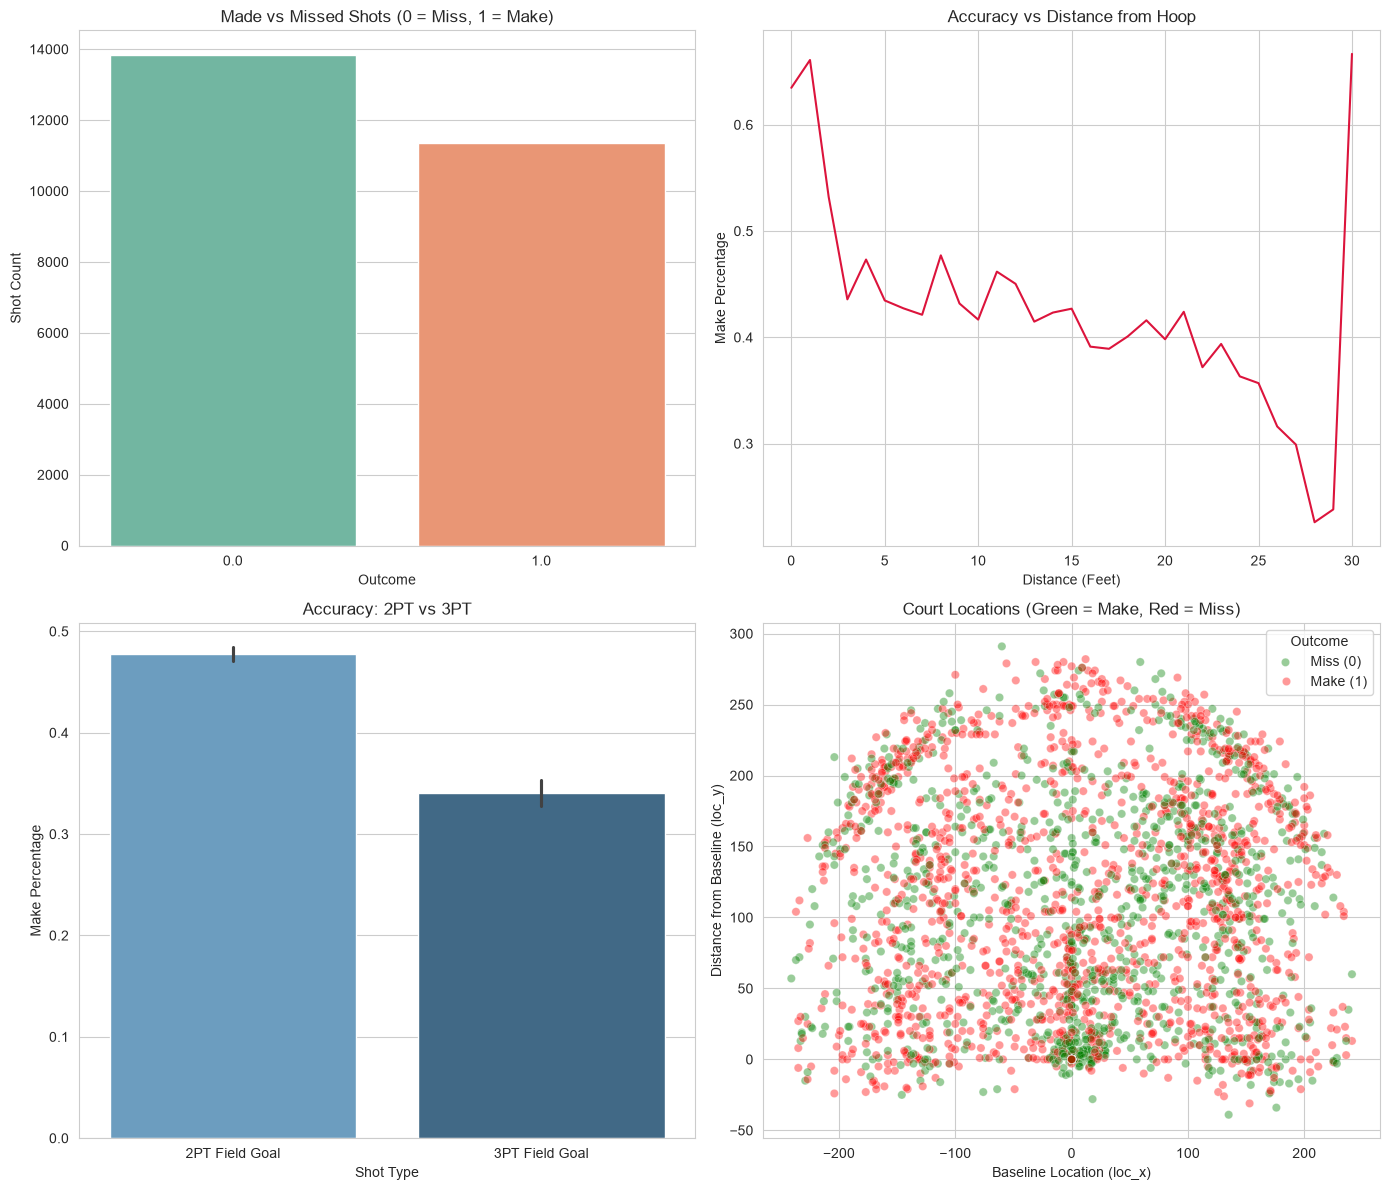

In [13]:
sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 2, figsize = (14, 12))

# Made vs missed shots
sns.countplot(ax = axes[0, 0], x = 'shot_made_flag', data = train_df, palette = 'Set2')
axes[0, 0].set_title('Made vs Missed Shots (0 = Miss, 1 = Make)')
axes[0, 0].set_xlabel('Outcome')
axes[0, 0].set_ylabel('Shot Count')

# How distance affects accuracy (cut off full-court heaves so the chart isn't stretched)
dist_stats = train_df.groupby('shot_distance')['shot_made_flag'].mean().reset_index()
dist_stats = dist_stats[dist_stats['shot_distance'] <= 35]
sns.lineplot(ax = axes[0, 1], x = 'shot_distance', y = 'shot_made_flag', data = dist_stats, color = 'crimson')
axes[0, 1].set_title('Accuracy vs Distance from Hoop')
axes[0, 1].set_xlabel('Distance (Feet)')
axes[0, 1].set_ylabel('Make Percentage')

# 2PT vs 3PT success rates
sns.barplot(ax = axes[1, 0], x = 'shot_type', y = 'shot_made_flag', data = train_df, palette = 'Blues_d')
axes[1, 0].set_title('Accuracy: 2PT vs 3PT')
axes[1, 0].set_xlabel('Shot Type')
axes[1, 0].set_ylabel('Make Percentage')

# Where the shots happened (3000 random shots so it doesn't look like an ink blob)
sns.scatterplot(
    ax = axes[1, 1],
    x = 'loc_x', y = 'loc_y',
    hue = 'shot_made_flag',
    data = train_df.sample(3000, random_state = 42),
    alpha = 0.4,
    palette = {0: 'red', 1: 'green'}
)
axes[1, 1].set_title('Court Locations (Green = Make, Red = Miss)')
axes[1, 1].set_xlabel('Baseline Location (loc_x)')
axes[1, 1].set_ylabel('Distance from Baseline (loc_y)')
axes[1, 1].legend(title = 'Outcome', labels = ['Miss (0)', 'Make (1)'])
fig.tight_layout()
plt.show()

### Observations

*   **Data size:** 30,697 shots in total. 5,000 have no outcome (`shot_made_flag` is missing), so those are the shots we must predict. The other 25,697 are labeled, and 25,183 remain after removing the top 2% outliers.
*   **Class balance:** Overall field goal percentage is about 45%, so misses are slightly more common than makes. Because of this, F1-score is reported next to accuracy.
*   **2PT vs 3PT:** 2-point shots go in about 47.7% of the time, 3-point shots only about 34.0%.
*   **Distance:** The line chart shows make percentage falling as the shot moves away from the hoop, so `shot_distance` should be a strong feature.
*   **Shot locations:** Most shots are taken close to the basket and along the 3-point arc.
*   **Home/away and playoffs:** The make % for these groups is printed above. They are included as features because they are cheap to add and may carry small signal.

# Model Creation

### Train / Validation Split

In [14]:
# Split first, so nothing from the validation rows leaks into encoding or scaling
train_part, val_part = train_test_split(
    train_df, test_size = 0.2, random_state = 42, stratify = train_df['shot_made_flag'])

y_train = train_part['shot_made_flag'].astype(int)
y_val = val_part['shot_made_flag'].astype(int)
print(f"Train: {len(train_part)} | Validation: {len(val_part)}")

Train: 20146 | Validation: 5037


### Target Encoding and Feature Standardization

In [15]:
categorical_cols = ['action_type', 'combined_shot_type', 'shot_type',
                    'shot_zone_area', 'shot_zone_basic', 'shot_zone_range']
scale_cols = numeric_features + ['period', 'season_num']

def target_encode(fit_df, apply_dfs, cols, smoothing = 20):
    # Replace each category with its (smoothed) make rate, learned ONLY from fit_df
    global_mean = fit_df['shot_made_flag'].mean()
    for col in cols:
        stats = fit_df.groupby(col)['shot_made_flag'].agg(['sum', 'count'])
        encoding = (stats['sum'] + smoothing * global_mean) / (stats['count'] + smoothing)
        for d in apply_dfs:
            # Unseen categories fall back to the overall average
            d[f'{col}_encoded'] = d[col].map(encoding).fillna(global_mean)

def prepare(fit_df, other_dfs):
    # Encode + scale using statistics from fit_df only, then apply the same to other_dfs
    fit_df = fit_df.copy()
    other_dfs = [d.copy() for d in other_dfs]
    target_encode(fit_df, [fit_df] + other_dfs, categorical_cols)

    features = [c for c in fit_df.columns if c not in categorical_cols + ['shot_made_flag']]
    scaler = StandardScaler()

    X_fit = fit_df[features].copy()
    X_fit[scale_cols] = scaler.fit_transform(X_fit[scale_cols])

    X_others = []
    for d in other_dfs:
        X = d[features].copy()
        X[scale_cols] = scaler.transform(X[scale_cols])
        X_others.append(X)
    return X_fit, X_others

X_train, (X_val,) = prepare(train_part, [val_part])
print(f"X_train: {X_train.shape} | X_val: {X_val.shape}")
X_train.head()

X_train: (20146, 14) | X_val: (5037, 14)


,loc_x,loc_y,period,playoffs,shot_distance,time_remaining,is_home,season_num,action_type_encoded,combined_shot_type_encoded,shot_type_encoded,shot_zone_area_encoded,shot_zone_basic_encoded,shot_zone_range_encoded
shot_id,,,,,,,,,,,,,,
23132,-0.060457,-1.078178,-0.454736,0,-1.461424,1.319397,0,-1.942351,0.389024,0.566789,0.478015,0.530817,0.619130,0.576715
545,-0.171351,-0.465313,-0.454736,0,-0.906018,-1.564911,0,-1.117307,0.742964,0.395469,0.478015,0.530817,0.462758,0.576715
29858,-1.058501,1.793875,1.279667,1,1.426687,-1.151477,1,1.151564,0.331199,0.395469,0.339262,0.364181,0.336441,0.338574
16060,0.457047,-1.030110,0.412465,0,-0.906018,-0.027910,1,0.739042,0.331199,0.395469,0.478015,0.530817,0.462758,0.576715
12113,-1.381941,1.673706,-1.321938,0,1.426687,0.653039,0,0.326520,0.331199,0.395469,0.339262,0.364181,0.336441,0.338574


### Evaluation Helper

In [16]:
results = []

def evaluate(name, model, X_val, y_val):
    # Hard 0/1 predictions for accuracy/F1/recall, probabilities for ROC-AUC
    pred = model.predict(X_val)
    proba = model.predict_proba(X_val)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, pred),
        'F1-Score': f1_score(y_val, pred),
        'Precision': precision_score(y_val, pred),
        'Recall': recall_score(y_val, pred),
        'ROC-AUC': roc_auc_score(y_val, proba)
    })

    print(f"--- {name} ---")
    print(f"accuracy: {results[-1]['Accuracy']:.4f}")
    print(f"f1_score: {results[-1]['F1-Score']:.4f}")
    print(f"recall_score: {results[-1]['Recall']:.4f}")
    print(f"roc_auc_score: {results[-1]['ROC-AUC']:.4f}")
    print("confusion_matrix (rows = actual, cols = predicted)\n", confusion_matrix(y_val, pred))
    print("classification report\n", classification_report(y_val, pred))

## Logistic Regression

In [17]:
lr_model = LogisticRegression(max_iter = 5000)
lr_model.fit(X_train, y_train)
evaluate('Logistic Regression', lr_model, X_val, y_val)

--- Logistic Regression ---
accuracy: 0.6824
f1_score: 0.5740
recall_score: 0.4749
roc_auc_score: 0.6996
confusion_matrix (rows = actual, cols = predicted)
 [[2359  408]
 [1192 1078]]
classification report
               precision    recall  f1-score   support

           0       0.66      0.85      0.75      2767
           1       0.73      0.47      0.57      2270

    accuracy                           0.68      5037
   macro avg       0.69      0.66      0.66      5037
weighted avg       0.69      0.68      0.67      5037



In [18]:
# Coefficients of the trained Logistic Regression (features are scaled, so they are comparable)
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lr_model.coef_[0]
})

# Sort by absolute value so the most impactful features are at the top
feature_importance['Abs_Coefficient'] = feature_importance['Coefficient'].abs()
feature_importance = feature_importance.sort_values(by = 'Abs_Coefficient', ascending = False)

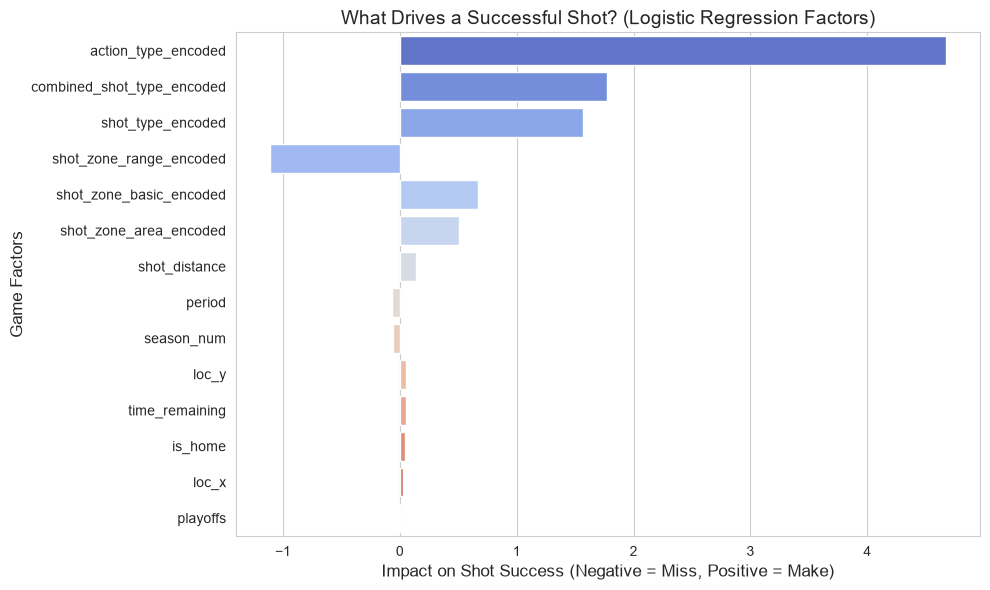

In [19]:
plt.figure(figsize = (10, 6))
sns.barplot(x = 'Coefficient', y = 'Feature', data = feature_importance, palette = 'coolwarm')
plt.title('What Drives a Successful Shot? (Logistic Regression Factors)', fontsize = 14)
plt.xlabel('Impact on Shot Success (Negative = Miss, Positive = Make)', fontsize = 12)
plt.ylabel('Game Factors', fontsize = 12)
plt.tight_layout()
plt.show()

# Random Forest

In [20]:
rf_model = RandomForestClassifier(n_estimators = 100, random_state = 42)
rf_model.fit(X_train, y_train)
evaluate('Random Forest (Base)', rf_model, X_val, y_val)

--- Random Forest (Base) ---
accuracy: 0.6512
f1_score: 0.5637
recall_score: 0.5000
roc_auc_score: 0.6712
confusion_matrix (rows = actual, cols = predicted)
 [[2145  622]
 [1135 1135]]
classification report
               precision    recall  f1-score   support

           0       0.65      0.78      0.71      2767
           1       0.65      0.50      0.56      2270

    accuracy                           0.65      5037
   macro avg       0.65      0.64      0.64      5037
weighted avg       0.65      0.65      0.64      5037



### Using GridSearchCV on Random Forest

In [21]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf_base = RandomForestClassifier(random_state = 42)
grid_search = GridSearchCV(estimator = rf_base, param_grid = param_grid,
                           cv = 3, n_jobs = -1, scoring = 'accuracy', verbose = 1)

print("Starting Grid Search... (This may take a few minutes)")
grid_search.fit(X_train, y_train)

print("\nBest Parameters found:", grid_search.best_params_)
best_rf_model = grid_search.best_estimator_
evaluate('Random Forest (Tuned)', best_rf_model, X_val, y_val)

Starting Grid Search... (This may take a few minutes)
Fitting 3 folds for each of 24 candidates, totalling 72 fits

Best Parameters found: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
--- Random Forest (Tuned) ---
accuracy: 0.6804
f1_score: 0.5674
recall_score: 0.4652
roc_auc_score: 0.7035
confusion_matrix (rows = actual, cols = predicted)
 [[2371  396]
 [1214 1056]]
classification report
               precision    recall  f1-score   support

           0       0.66      0.86      0.75      2767
           1       0.73      0.47      0.57      2270

    accuracy                           0.68      5037
   macro avg       0.69      0.66      0.66      5037
weighted avg       0.69      0.68      0.67      5037



# Gradient Boosting

In [22]:
gb_model = GradientBoostingClassifier(n_estimators = 100, random_state = 42)
gb_model.fit(X_train, y_train)
evaluate('Gradient Boosting', gb_model, X_val, y_val)

--- Gradient Boosting ---
accuracy: 0.6831
f1_score: 0.5682
recall_score: 0.4626
roc_auc_score: 0.7033
confusion_matrix (rows = actual, cols = predicted)
 [[2391  376]
 [1220 1050]]
classification report
               precision    recall  f1-score   support

           0       0.66      0.86      0.75      2767
           1       0.74      0.46      0.57      2270

    accuracy                           0.68      5037
   macro avg       0.70      0.66      0.66      5037
weighted avg       0.70      0.68      0.67      5037



# Cross Validation

In [23]:
# 5-Fold CV on the training part only (validation rows stay untouched)
# Run on both Logistic Regression and the tuned Random Forest
cv_models = {
    'Logistic Regression': LogisticRegression(max_iter = 5000),
    'Random Forest (Tuned)': RandomForestClassifier(**grid_search.best_params_, random_state = 42)
}

cv_summary = []
for name, cv_model in cv_models.items():
    print(f"Running 5-Fold Cross-Validation for {name}...")
    acc = cross_val_score(cv_model, X_train, y_train, cv = 5, scoring = 'accuracy', n_jobs = -1)
    f1 = cross_val_score(cv_model, X_train, y_train, cv = 5, scoring = 'f1', n_jobs = -1)
    cv_summary.append({'Model': name,
                       'CV Accuracy (mean)': acc.mean(), 'CV Accuracy (std)': acc.std(),
                       'CV F1 (mean)': f1.mean(), 'CV F1 (std)': f1.std()})

pd.DataFrame(cv_summary).round(4)

Running 5-Fold Cross-Validation for Logistic Regression...
Running 5-Fold Cross-Validation for Random Forest (Tuned)...


,Model,CV Accuracy (mean),CV Accuracy (std),CV F1 (mean),CV F1 (std)
0,Logistic Regression,0.6787,0.0108,0.5666,0.0141
1,Random Forest (Tuned),0.6793,0.0101,0.5637,0.0139


**Cross-Validation Verification:**

| Model | CV Accuracy (mean) | CV Accuracy (std) | CV F1 (mean) | CV F1 (std) |
|---|---|---|---|---|
| Logistic Regression | 0.6787 | 0.0108 | 0.5666 | 0.0141 |
| Random Forest (Tuned) | 0.6793 | 0.0101 | 0.5637 | 0.0139 |

A 5-fold cross-validation was run on the training data to check that the results were not caused by a lucky split. Both models score about 67.9% accuracy, with a standard deviation of about 0.01 (one percentage point) across folds, so the scores are stable. The two models are again tied: the difference in mean accuracy is 0.06 points, which is well inside the fold-to-fold variation. This supports choosing the simpler Logistic Regression.

## Model Comparison Report

**Objective:** Evaluate multiple classification models to determine the most effective algorithm for predicting shot outcomes and advising stakeholders on game strategy.

All numbers below are measured on the same held-out validation set. Encoding and scaling were fitted on the training rows only.

In [24]:
results_df = pd.DataFrame(results).sort_values('Accuracy', ascending = False).reset_index(drop = True)
results_df.round(4)

,Model,Accuracy,F1-Score,Precision,Recall,ROC-AUC
0,Gradient Boosting,0.6831,0.5682,0.7363,0.4626,0.7033
1,Logistic Regression,0.6824,0.5740,0.7254,0.4749,0.6996
2,Random Forest (Tuned),0.6804,0.5674,0.7273,0.4652,0.7035
3,Random Forest (Base),0.6512,0.5637,0.6460,0.5000,0.6712


In [25]:
# Decision rule: if the best model beats Logistic Regression by less than 1 percentage point
# of accuracy, the gap is noise, so pick the simpler Logistic Regression
lr_acc = results_df.loc[results_df['Model'] == 'Logistic Regression', 'Accuracy'].iloc[0]
best_name = results_df.loc[0, 'Model']
gap = results_df.loc[0, 'Accuracy'] - lr_acc

if gap < 0.01:
    final_name = 'Logistic Regression'
    print(f"Best model: {best_name}. Its accuracy gap over Logistic Regression is only {gap*100:.2f} points.")
    print("The models perform about the same, so we pick the simpler Logistic Regression.")
else:
    final_name = best_name
    print(f"{best_name} beats Logistic Regression by {gap*100:.2f} points, so we pick it.")

print("Final model:", final_name)

Best model: Gradient Boosting. Its accuracy gap over Logistic Regression is only 0.08 points.
The models perform about the same, so we pick the simpler Logistic Regression.
Final model: Logistic Regression


**Conclusion & Recommendation for Production:**

| Model | Accuracy | F1-Score | Precision | Recall | ROC-AUC |
|---|---|---|---|---|---|
| Gradient Boosting | 0.6831 | 0.5682 | 0.7363 | 0.4626 | 0.7033 |
| **Logistic Regression** | 0.6824 | **0.5740** | 0.7254 | 0.4749 | 0.6996 |
| Random Forest (Tuned) | 0.6804 | 0.5674 | 0.7273 | 0.4652 | 0.7035 |
| Random Forest (Base) | 0.6512 | 0.5637 | 0.6460 | 0.5000 | 0.6712 |

Gradient Boosting, Logistic Regression and the tuned Random Forest are within 0.3 percentage points of each other in accuracy, so there is no real winner on accuracy. Logistic Regression has the best F1-Score (0.5740), and it is the simplest and easiest to explain, so it is the recommended model for production. Tuning improved the Random Forest from 65.1% to 68.0% accuracy, but it did not beat the simpler models.

Precision (about 0.73) is higher than recall (about 0.47). When the model predicts a make it is right about 73% of the time, but it misses more than half of the actual makes. Shot outcomes have a lot of randomness, so about 68% accuracy is a reasonable ceiling for the features available.

# Predictions on the Missing Shots

In [26]:
# Refit the final model on ALL labeled shots, then predict the 5000 shots with missing outcome
final_models = {
    'Logistic Regression': LogisticRegression(max_iter = 5000),
    'Random Forest (Tuned)': RandomForestClassifier(**grid_search.best_params_, random_state = 42),
    'Random Forest (Base)': RandomForestClassifier(n_estimators = 100, random_state = 42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators = 100, random_state = 42)
}

X_full, (X_test,) = prepare(train_df, [test_df])
y_full = train_df['shot_made_flag'].astype(int)

final_model = final_models[final_name]
final_model.fit(X_full, y_full)

test_df['shot_made_flag'] = final_model.predict(X_test)
test_df['made_probability'] = final_model.predict_proba(X_test)[:, 1]

test_df[['shot_made_flag', 'made_probability']].to_csv('NBA_shot_predictions.csv')
print(f"Saved {len(test_df)} predictions to NBA_shot_predictions.csv")
test_df[['shot_made_flag', 'made_probability']].head()

Saved 5000 predictions to NBA_shot_predictions.csv


,shot_made_flag,made_probability
shot_id,,
1,0,0.393106
8,0,0.289506
17,1,0.783837
20,1,0.791473
33,0,0.392988


## Challenges Faced

| # | Challenge | Solution Used | Reason / Outcome |
|---|-----------|---------------|------------------|
| 1 | **Many text categories** (shot types like "Jump Shot", "Dunk"). One-hot encoding would create too many columns and slow the models. | Smoothed Target Encoding | Each category becomes its make-percentage. Smoothing pulls rare categories toward the overall average so they are not over-trusted. |
| 2 | **Data leakage.** Encoding was built from all labeled rows and scaling ran after the split, so validation scores were too optimistic. | Split first, then fit encoding and scaler on training rows only | Validation data now behaves like unseen data, so the reported scores are honest. |
| 3 | **Outliers and desperation shots** such as full-court heaves at the buzzer confuse the model. | Isolation Forest (top 2% removed) | The model learns from normal plays based on location, distance and time. |
| 4 | **Redundant location data.** `lat`/`lon` repeat `loc_x`/`loc_y`, which makes linear models unstable. | Feature Elimination (dropped `lat`, `lon`) | Same information, less noise. |
| 5 | **Useful text columns the model cannot read** (`matchup`, `season`, `game_date`). | Feature Engineering | `matchup` became a home/away flag, `season` became a numeric year, and the raw text was dropped. |
| 6 | **Models scoring almost the same.** Naming a winner from a tiny gap would be misleading. | `GridSearchCV` (72 fits) plus a decision rule | A gap under 1 percentage point is treated as noise, so the simpler Logistic Regression is chosen. 5-fold CV checks that scores are stable. |
| 7 | **Missing outcomes.** 5,000 shots have no `shot_made_flag`. | Labeled/unlabeled split, final model refitted on all labeled shots | The 5,000 shots are predicted at the end and saved to `NBA_shot_predictions.csv`. |